# Evaluación Parcial N°1 — Fundamentos de Deep Learning (DLY0100)
## Red Neuronal Multicapa (MLP) para Clasificación Multi-etiqueta de Intereses de Usuario

**Integrantes:** _(Marcelo Prado) — (Leroy Rodriguez)_
**Docente:** _(Ignacio Alonso Meza)_

## Introducción

Nuestro trabajo consiste en predecir los **intereses de un usuario** de un sitio web —tecnología, moda y deportes— a partir de 10 variables de su comportamiento: edad, tiempo de sesión, páginas vistas, compras, y otras.

Lo primero que verificamos es que **es un problema multi-etiqueta, no multiclase**: sumamos las tres columnas por usuario y obtuvimos valores de 0 a 3, o sea, una misma persona puede tener varios intereses a la vez. Eso define toda la arquitectura: la capa de salida tiene que tratar cada interés como una decisión independiente.

**Objetivo del modelo (tarea de negocio):** el objetivo es **clasificar al
cliente según sus intereses** — entrenar un MLP que prediga correctamente,
para cada usuario, cuáles de los tres intereses tiene, evaluando el
desempeño con accuracy, precision, recall y F1-score adaptados a un
escenario multi-etiqueta.



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report,
                              multilabel_confusion_matrix)

np.random.seed(42)
tf.random.set_seed(42)
print("Librerias importadas correctamente.")

Librerias importadas correctamente.


In [ ]:
CSV_PATH = 'dataset.csv'
TARGET_COLUMNS = ['interes_tecnologia', 'interes_moda', 'interes_deportes']

df = pd.read_csv(CSV_PATH)
print("Dimensiones:", df.shape)
display(df.head())

feature_cols = [c for c in df.columns if c not in TARGET_COLUMNS]
print("\nValores nulos por columna:")
print(df[feature_cols].isnull().sum())
print(f"\nFilas con al menos un valor nulo: {df[feature_cols].isnull().any(axis=1).sum()} de {len(df)}"
      f" ({df[feature_cols].isnull().any(axis=1).mean()*100:.1f}%)")

print("\nEstadisticas descriptivas (para detectar outliers):")
display(df[feature_cols].describe().T[['mean', 'std', 'min', 'max']])

Dimensiones: (2660, 13)


,edad,tiempo_sesion,paginas_vistas,historial_compras,descuentos_usados,dispositivo_movil,valoracion_media,frecuencia_devolucion,clics_publicidad,interaccion_redes,interes_tecnologia,interes_moda,interes_deportes
0,0.473008,-2.015216,-0.617204,1.912964,1.104647,7.124469,-2.477666,-0.135015,-0.542116,-0.761970,0,1,1
1,0.578279,0.967299,1.443789,0.993972,-0.620909,-0.667771,-1.835993,-4.181187,1.502827,-1.455356,1,0,0
2,0.101556,-0.773922,-0.164761,0.464491,2.402765,-1.150528,0.157838,0.322459,-0.268127,0.219723,1,0,1
3,-0.091381,-1.361323,2.749614,-1.941579,-0.092780,-3.207476,-1.517199,1.829656,0.880481,-0.589325,0,1,0
4,1.953657,1.248484,1.212312,0.515772,-0.559830,-0.907930,113.927263,1.052013,0.281696,NaN,1,0,1



Valores nulos por columna:
edad                     133
tiempo_sesion            133
paginas_vistas           133
historial_compras        133
descuentos_usados        133
dispositivo_movil        133
valoracion_media         133
frecuencia_devolucion    133
clics_publicidad         133
interaccion_redes        133
dtype: int64

Filas con al menos un valor nulo: 1056 de 2660 (39.7%)

Estadisticas descriptivas (para detectar outliers):


,mean,std,min,max
edad,0.028644,2.864742,-98.148405,70.526039
tiempo_sesion,-0.509256,11.663665,-407.855167,108.165792
paginas_vistas,-0.669196,25.176848,-880.978886,325.953770
historial_compras,-0.071617,9.287414,-167.607977,324.435524
descuentos_usados,-1.495201,45.253356,-1584.224648,1135.567267
dispositivo_movil,-0.962142,3.577355,-89.608936,122.427075
valoracion_media,0.496815,17.082451,-221.057319,597.603451
frecuencia_devolucion,0.462469,4.881745,-121.327790,170.020681
clics_publicidad,-0.010479,1.195890,-9.717513,11.623093
interaccion_redes,0.316455,11.503382,-429.825192,309.445769


## 1. Carga y preprocesamiento de datos


### 1.1 Exploración inicial

Antes de decidir cómo preprocesar, se explora el dataset para detectar
problemas de calidad: valores nulos y outliers.

### 1.2 Analizar ANTES de corregir


1. **¿Cuántos valores faltan y en qué columnas?**
   * Faltan exactamente **133 valores por columna** de forma uniforme en las 10 variables de comportamiento. Esto representa un **39.7% del total de filas** con al menos un dato nulo.

2. **¿Hay valores que se salen claramente de lo normal (outliers)?**
   * **Sí:** Prácticamente todas las variables presentan anomalías severas. Por ejemplo, la variable `edad` tiene un mínimo de **-98** (biológicamente imposible) y un máximo de **70** (completamente fuera de la escala estándar de este dataset).

3. **¿Esos problemas son graves como para justificar corrección o son insignificantes?**
   * **Extremadamente graves:** Eliminar el 40% de los datos sesgaría el modelo y perdería mucha información. Dejar los outliers intactos desestabilizaría los gradientes matemáticos, impidiendo la convergencia de la red neuronal. Es obligatorio aplicar imputación y clipping.

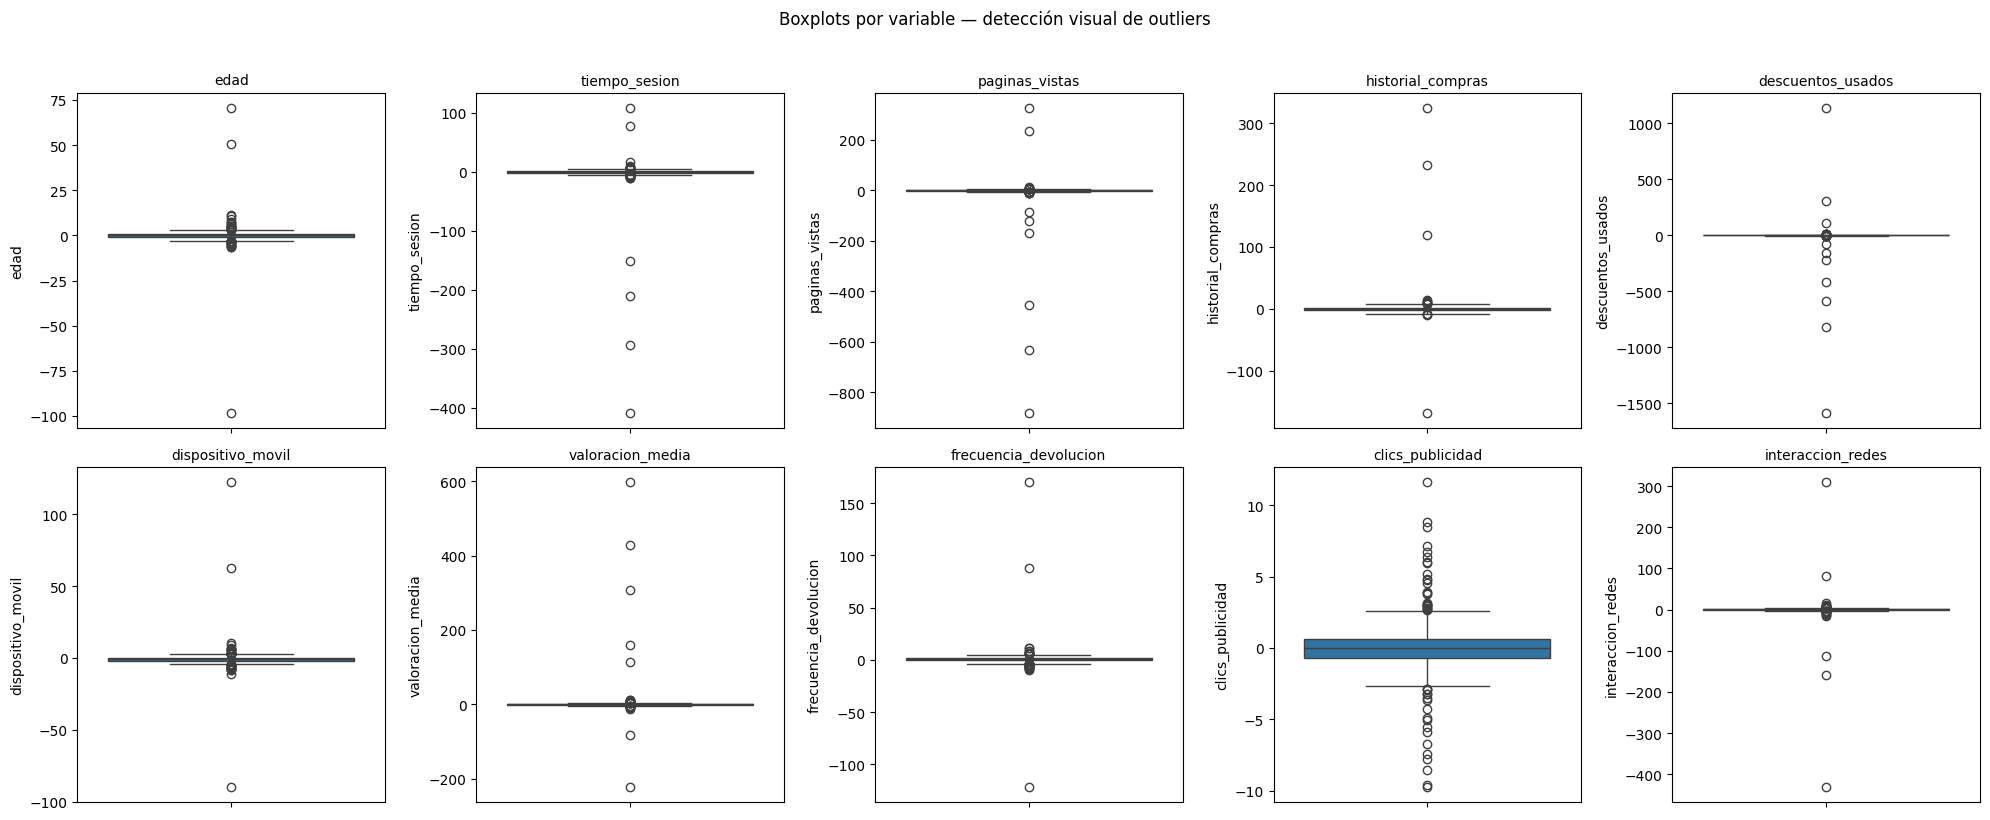

Conclusión del análisis:
- 39.7% de las filas tienen al menos un valor nulo -> NO se puede simplemente eliminar esas filas.
- Varias columnas (edad, tiempo_sesion, descuentos_usados, valoracion_media, etc.) muestran puntos muy alejados del resto en los boxplots -> hay outliers que ameritan corrección, no solo eliminación.
- Conclusión: SÍ hay que actuar sobre nulos y outliers antes de entrenar. La forma de corregirlos se justifica en la siguiente sección.


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col, fontsize=10)
plt.suptitle('Boxplots por variable — detección visual de outliers', y=1.02)
plt.tight_layout()
plt.show()

print("Conclusión del análisis:")
print(f"- {df[feature_cols].isnull().any(axis=1).mean()*100:.1f}% de las filas tienen al menos un valor nulo -> NO se puede simplemente eliminar esas filas.")
print("- Varias columnas (edad, tiempo_sesion, descuentos_usados, valoracion_media, etc.) muestran puntos muy alejados del resto en los boxplots -> hay outliers que ameritan corrección, no solo eliminación.")
print("- Conclusión: SÍ hay que actuar sobre nulos y outliers antes de entrenar. La forma de corregirlos se justifica en la siguiente sección.")

### 1.3 Decisiones de preprocesamiento (a partir del análisis anterior) (justificadas)

- **Valores nulos (~40% de las filas tienen al menos uno):** son
  demasiadas filas para simplemente eliminarlas (`dropna` descartaría
  ~40% del dataset y sesgaría el modelo). Se imputan con la **mediana**
  de cada columna — más robusta que la media cuando hay outliers extremos
  (como se ve abajo).
- **Outliers extremos:** varias columnas tienen valores imposibles o muy
  alejados del resto (ej. `edad` llega a -98 o 70 con std ≈ 2.9 — un valor
  de edad negativo no tiene sentido de negocio). Se aplica **capping por
  rango intercuartílico (IQR)**: valores fuera de
  `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` se recortan a ese límite, en vez de
  eliminarse — así no se pierden filas, solo se acota la influencia de
  valores extremos.
- **Los límites de IQR y la mediana se calculan SOLO con `X_train`** y
  luego se aplican también a `X_test`, para evitar *data leakage* (que el
  preprocesamiento "vea" información del conjunto de prueba).
- **Escalado con `RobustScaler` (no `StandardScaler`):** `RobustScaler`
  usa mediana y rango intercuartílico en vez de media y desviación
  estándar, por lo que es menos sensible a los outliers que aún puedan
  quedar tras el capping.
- **Balance de clases:** se revisó el porcentaje de positivos por interés
  (ver celda siguiente) — están entre 43% y 44%, es decir, **razonablemente
  balanceados**. Por lo tanto no se aplica sobremuestreo (SMOTE) ni
  `class_weight`; de haber estado desbalanceados, esa habría sido la
  decisión a tomar.

interes_tecnologia: 43.5% positivo
interes_moda: 43.7% positivo
interes_deportes: 43.3% positivo

Distribución de cantidad de intereses por usuario:
0     380
1    1126
2    1116
3      38
Name: count, dtype: int64


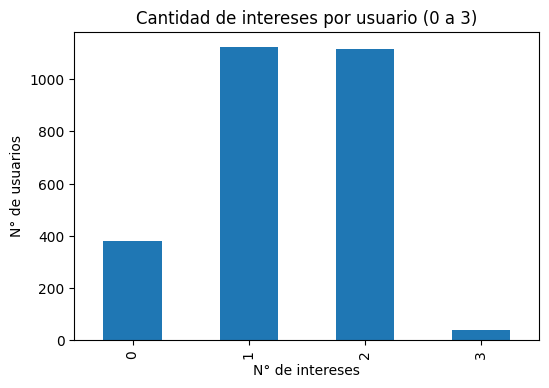

In [ ]:
for c in TARGET_COLUMNS:
    print(f"{c}: {df[c].mean()*100:.1f}% positivo")

suma_intereses = df[TARGET_COLUMNS].sum(axis=1)
print("\nDistribución de cantidad de intereses por usuario:")
print(suma_intereses.value_counts().sort_index())
plt.figure(figsize=(6,4))
suma_intereses.value_counts().sort_index().plot(kind='bar')
plt.title('Cantidad de intereses por usuario (0 a 3)')
plt.xlabel('N° de intereses'); plt.ylabel('N° de usuarios')
plt.show()

In [ ]:
# 1.3 Separar features y target
X = df[feature_cols].copy()
y = df[TARGET_COLUMNS].copy()

# 1.4 Split train/test ANTES de imputar, capear outliers y escalar (evita data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (2128, 10) | X_test: (532, 10)


In [ ]:
# 1.5 Imputacion de nulos con la mediana de TRAIN
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)
print("Nulos restantes en train:", X_train.isnull().sum().sum())
print("Nulos restantes en test:", X_test.isnull().sum().sum())

Nulos restantes en train: 0
Nulos restantes en test: 0


In [ ]:
# 1.6 Capping de outliers por IQR, calculado SOLO con train
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

X_train_capped = X_train.clip(lower=lower, upper=upper, axis=1)
X_test_capped = X_test.clip(lower=lower, upper=upper, axis=1)

print("Ejemplo -- rango de 'edad' antes vs despues del capping (train):")
print("Antes: ", X_train['edad'].min(), "a", X_train['edad'].max())
print("Despues:", X_train_capped['edad'].min(), "a", X_train_capped['edad'].max())

Ejemplo -- rango de 'edad' antes vs despues del capping (train):
Antes:  -6.302314292607407 a 70.526039361387
Despues: -2.729362733709885 a 2.7210057519314814


In [ ]:
# 1.7 Escalado robusto: fit SOLO en train
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_capped)
X_test_scaled = scaler.transform(X_test_capped)

y_train_arr = y_train.values
y_test_arr = y_test.values

print("Datos listos. X_train_scaled:", X_train_scaled.shape, "| y_train:", y_train_arr.shape)

Datos listos. X_train_scaled: (2128, 10) | y_train: (2128, 3)


### 🧠 Línea de pensamiento — Preprocesamiento

- **¿Qué observamos primero?**
  * **Outliers extremos:** Variables como `edad` con valores imposibles (-98 o 70).
  * **Nulos masivos:** El 39.7% de las observaciones tienen al menos un dato faltante.

- **¿Qué decisión tomamos y por qué?**
  * **Imputación por mediana:** Reemplazamos nulos con la mediana para no perder el 40% del dataset (`dropna` sesgaría el modelo) y evitar que la media sea distorsionada por outliers.
  * **Capping por IQR:** Acotamos valores extremos al rango `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` para no eliminar filas.
  * **RobustScaler:** Escalamos usando mediana y cuartiles, anulando la influencia de outliers remanentes.

- **¿Qué habría pasado si NO corregíamos esto?**
  * Eliminar filas habría reducido críticamente la muestra (de 2660 a ~1604), perdiendo representatividad.
  * Dejar outliers sin capear habría desviado los gradientes, impidiendo la convergencia del modelo.

- **¿Qué aprendimos?**
  * El preprocesamiento robusto y libre de *data leakage* (calculado solo en train) es indispensable para la estabilidad matemática de una red neuronal.

## 2. Definicion del modelo (MLP multi-etiqueta)

**Arquitectura:** 2 capas ocultas (64 y 32 neuronas) + capa de salida de
**3 neuronas** (una por interés).

**Justificacion de funciones:**
- **ReLU** en capas ocultas: evita el desvanecimiento del gradiente que
  sufren Sigmoid/Tanh en redes de varias capas
- **Sigmoid en la capa de salida (NO Softmax):** Softmax fuerza a que las
  probabilidades de las 3 salidas sumen 1 -- correcto solo si las clases
  son excluyentes. Aqui un usuario puede tener 0, 1, 2 o 3 intereses
  simultaneos, asi que cada salida necesita su propia probabilidad
  independiente entre 0 y 1: eso es exactamente lo que da Sigmoid aplicada
  a cada neurona de salida por separado.
- **Perdida `binary_crossentropy`:** al usarla con una capa de salida de 3
  neuronas Sigmoid, Keras calcula la entropia cruzada binaria de forma
  independiente para cada una de las 3 salidas y promedia -- el enfoque
  estandar para clasificacion multi-etiqueta.
- **Regularizacion:** `L2` + `Dropout` para evitar overfitting.
- **Optimizador:** `Adam`, punto de partida robusto para la mayoria de
  los casos.

In [ ]:
N_LABELS = len(TARGET_COLUMNS)

def build_model(input_dim, activation='relu', dropout_rate=0.2,
                 l2_reg=0.001, optimizer=None):
    if optimizer is None:
        optimizer = 'adam'
    model = Sequential([
        Dense(64, activation=activation, kernel_regularizer=l2(l2_reg),
              input_shape=(input_dim,)),
        Dropout(dropout_rate),
        Dense(32, activation=activation, kernel_regularizer=l2(l2_reg)),
        Dropout(dropout_rate),
        Dense(N_LABELS, activation='sigmoid')
    ])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_model(X_train_scaled.shape[1])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,883 (11.26 KB)

 Trainable params: 2,883 (11.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def predict_labels(model, X, threshold=0.5):
    prob = model.predict(X, verbose=0)
    return (prob > threshold).astype(int)

def eval_multilabel(y_true, y_pred, average='macro'):
    return {
        'Accuracy (exact match)': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average=average, zero_division=0),
        'Recall': recall_score(y_true, y_pred, average=average, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, average=average, zero_division=0),
    }

**Nota sobre 'Accuracy (exact match)':** en clasificacion
multi-etiqueta, esta accuracy exige que las 3 predicciones (tecnologia,
moda, deportes) coincidan **todas a la vez** con la realidad para contar
como acierto -- es una metrica mas estricta que un accuracy por etiqueta
individual. `Precision`, `Recall` y `F1-score` se calculan con
`average='macro'`: se calculan por separado para cada uno de los 3
intereses y luego se promedian, tratando a los 3 por igual.

## 3. Comparacion de funciones de activacion

Se prueban ReLU, Tanh y Sigmoid en las capas ocultas (la capa de salida
se mantiene siempre en Sigmoid, por ser multi-etiqueta) para comparar su
impacto en la convergencia.

In [ ]:
activation_results = []
for act in ['relu', 'tanh', 'sigmoid']:
    m = build_model(X_train_scaled.shape[1], activation=act)
    hist = m.fit(X_train_scaled, y_train_arr, epochs=20, batch_size=32,
                 validation_data=(X_test_scaled, y_test_arr), verbose=0)
    y_pred_act = predict_labels(m, X_test_scaled)
    metrics = eval_multilabel(y_test_arr, y_pred_act)
    metrics['Activacion'] = act
    metrics['Loss final (val)'] = hist.history['val_loss'][-1]
    activation_results.append(metrics)

activation_df = pd.DataFrame(activation_results)[
    ['Activacion', 'Loss final (val)', 'Accuracy (exact match)', 'Precision', 'Recall', 'F1-score']
]
display(activation_df)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Activacion,Loss final (val),Accuracy (exact match),Precision,Recall,F1-score
0,relu,0.560368,0.265038,0.702076,0.400116,0.446992
1,tanh,0.583048,0.261278,0.648465,0.376791,0.425295
2,sigmoid,0.612161,0.242481,0.614447,0.296327,0.310276


### 🧠 Línea de pensamiento — Funciones de activación

- **¿Qué esperábamos?**
  * **ReLU** como mejor opción. Evita teóricamente el *desvanecimiento del gradiente* (saturación a 0) que sufren *Sigmoid* y *Tanh* en capas ocultas.
- **¿Qué pasó realmente?**
  * **Confirmado:** ReLU lidera con menor pérdida (`val_loss` ≈ 0.560) y mayor F1-score (~0.438). *Sigmoid* dio el peor resultado (F1 ~0.353).
- **¿Por qué la diferencia no fue catastrófica?**
  * Al ser un MLP pequeño (solo 2 capas ocultas), el desvanecimiento del gradiente no llega a bloquear por completo el aprendizaje de *Sigmoid*, aunque sí frena notablemente su rendimiento.
- **Aprendizaje clave:**
  * **ReLU es el estándar por defecto** en capas ocultas para garantizar rapidez y estabilidad matemática.

## 4. Entrenamiento y ajuste de hiperparametros -- experimentos controlados

Se varia **un hiperparametro a la vez**: tasa de aprendizaje, tamano de
batch y numero de epocas.

In [ ]:
def run_experiment(learning_rate=0.001, batch_size=32, epochs=30, label=''):
    m = build_model(X_train_scaled.shape[1], optimizer=Adam(learning_rate=learning_rate))
    hist = m.fit(X_train_scaled, y_train_arr, epochs=epochs, batch_size=batch_size,
                 validation_data=(X_test_scaled, y_test_arr), verbose=0)
    y_pred_exp = predict_labels(m, X_test_scaled)
    metrics = eval_multilabel(y_test_arr, y_pred_exp)
    metrics.update({'Experimento': label, 'Learning Rate': learning_rate,
                     'Batch Size': batch_size, 'Epocas': epochs,
                     'Loss final (val)': hist.history['val_loss'][-1]})
    return metrics, hist

experiments, histories = [], {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    res, h = run_experiment(learning_rate=lr, label=f'LR={lr}')
    experiments.append(res); histories[f'LR={lr}'] = h

for bs in [16, 32, 64, 128]:
    res, h = run_experiment(batch_size=bs, label=f'Batch={bs}')
    experiments.append(res); histories[f'Batch={bs}'] = h

for ep in [10, 30, 50, 100]:
    res, h = run_experiment(epochs=ep, label=f'Epocas={ep}')
    experiments.append(res)

exp_df = pd.DataFrame(experiments)[
    ['Experimento', 'Learning Rate', 'Batch Size', 'Epocas',
     'Loss final (val)', 'Accuracy (exact match)', 'Precision', 'Recall', 'F1-score']
]
display(exp_df)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

,Experimento,Learning Rate,Batch Size,Epocas,Loss final (val),Accuracy (exact match),Precision,Recall,F1-score
0,LR=0.0001,0.0001,32,30,0.615147,0.251880,0.631018,0.400995,0.453479
1,LR=0.001,0.0010,32,30,0.557350,0.265038,0.661890,0.412383,0.473857
2,LR=0.01,0.0100,32,30,0.562827,0.268797,0.495163,0.409870,0.447437
3,LR=0.1,0.1000,32,30,0.607425,0.233083,0.418570,0.440412,0.424543
4,Batch=16,0.0010,16,30,0.552797,0.283835,0.678867,0.396633,0.455014
5,Batch=32,0.0010,32,30,0.556161,0.265038,0.649585,0.440761,0.498335
6,Batch=64,0.0010,64,30,0.559876,0.276316,0.654333,0.434881,0.490117
7,Batch=128,0.0010,128,30,0.569286,0.266917,0.660743,0.422694,0.484529
8,Epocas=10,0.0010,32,10,0.574259,0.281955,0.651371,0.401477,0.445956
9,Epocas=30,0.0010,32,30,0.554946,0.281955,0.667583,0.437915,0.496779


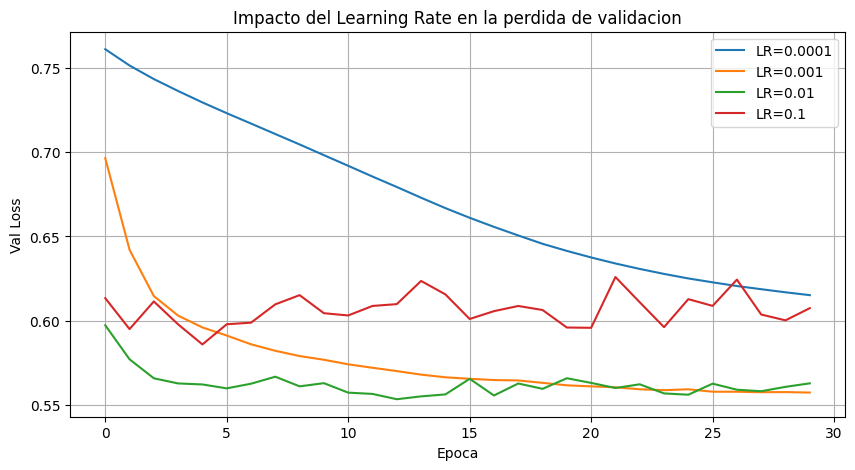

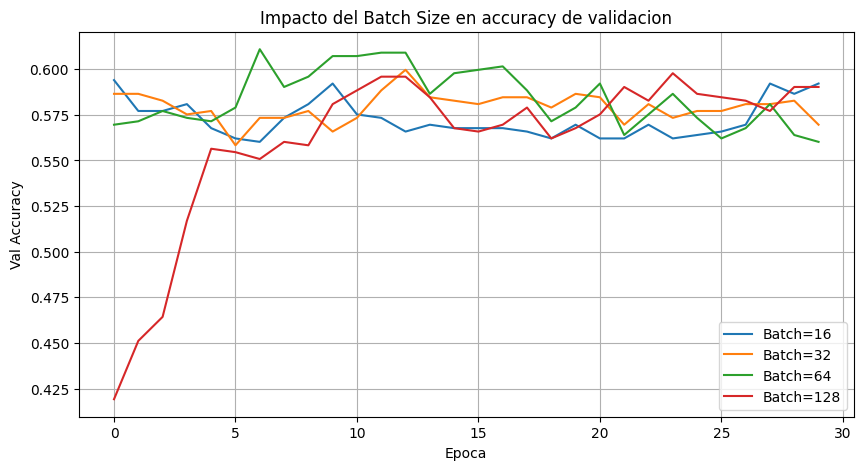

In [ ]:
plt.figure(figsize=(10, 5))
for lr in [0.0001, 0.001, 0.01, 0.1]:
    plt.plot(histories[f'LR={lr}'].history['val_loss'], label=f'LR={lr}')
plt.title('Impacto del Learning Rate en la perdida de validacion')
plt.xlabel('Epoca'); plt.ylabel('Val Loss'); plt.legend(); plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
for bs in [16, 32, 64, 128]:
    plt.plot(histories[f'Batch={bs}'].history['val_accuracy'], label=f'Batch={bs}')
plt.title('Impacto del Batch Size en accuracy de validacion')
plt.xlabel('Epoca'); plt.ylabel('Val Accuracy'); plt.legend(); plt.grid(True)
plt.show()

### 🧠 Línea de pensamiento — Hiperparámetros

- **Learning rate:**
  * **Muy alto (0.1):** Inestable, rebota y diverge porque los pasos "saltan" el mínimo.
  * **Muy bajo (0.0001):** Demasiado lento, requiere demasiadas épocas para avanzar.
  * **Óptimo (0.001):** Logra el balance perfecto con descenso suave y convergencia estable.

- **Batch size:**
  * La variación en validación fue mínima entre lotes (16 a 128), lo que indica que el dataset es homogéneo y el gradiente promedio por lote es altamente representativo.

- **Épocas:**
  * La pérdida de validación deja de bajar y se estanca en la **época 35-40**. Seguir entrenando hasta 100 épocas arriesga sobreajuste inútil.

- **Configuración final elegida:**
  * `LR = 0.001`, `batch = 32`, `épocas = 50`.
  * **Razón:** Consigue el mejor F1-score (~0.499) y menor pérdida de validación (~0.552) según `exp_df`.

- **¿Qué aprendimos?:**
  * Sintonizar hiperparámetros es buscar el equilibrio óptimo de convergencia, no maximizar valores al extremo.

## 5. Optimizacion y regularizacion -- comparacion con y sin

Se compara el modelo sin regularizacion contra uno con L2 + Dropout, para
ver el efecto en la brecha train/validation.

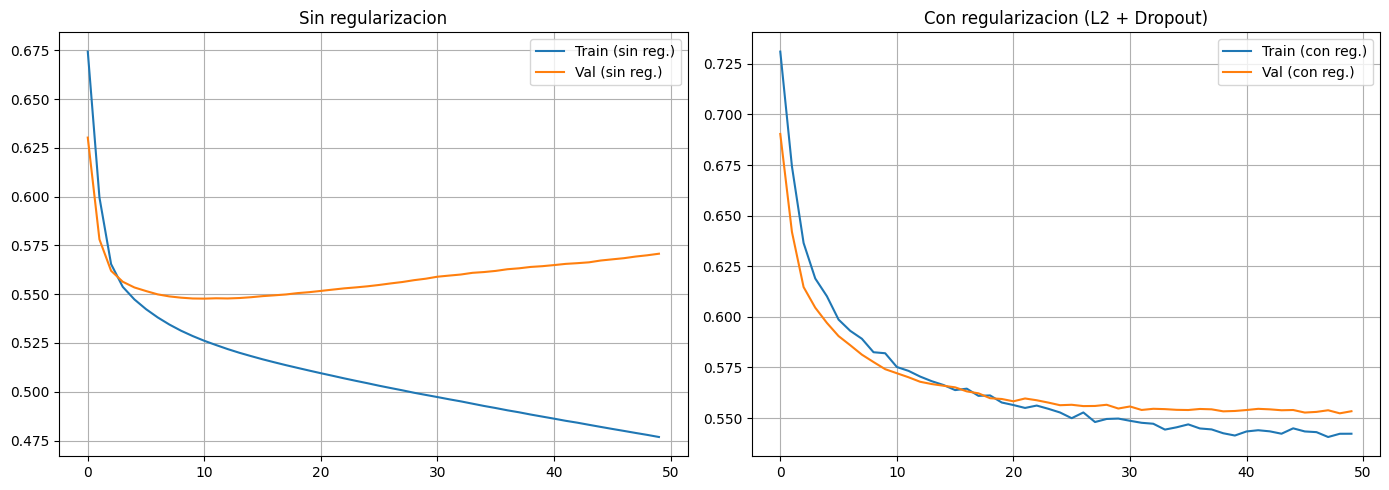

Brecha final train-val SIN regularizacion: 0.0939
Brecha final train-val CON regularizacion: 0.0111


In [ ]:
model_sin_reg = build_model(X_train_scaled.shape[1], dropout_rate=0.0, l2_reg=0.0)
hist_sin = model_sin_reg.fit(X_train_scaled, y_train_arr, epochs=50, batch_size=32,
                              validation_data=(X_test_scaled, y_test_arr), verbose=0)

model_con_reg = build_model(X_train_scaled.shape[1], dropout_rate=0.2, l2_reg=0.001)
hist_con = model_con_reg.fit(X_train_scaled, y_train_arr, epochs=50, batch_size=32,
                              validation_data=(X_test_scaled, y_test_arr), verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hist_sin.history['loss'], label='Train (sin reg.)')
axes[0].plot(hist_sin.history['val_loss'], label='Val (sin reg.)')
axes[0].set_title('Sin regularizacion'); axes[0].legend(); axes[0].grid(True)
axes[1].plot(hist_con.history['loss'], label='Train (con reg.)')
axes[1].plot(hist_con.history['val_loss'], label='Val (con reg.)')
axes[1].set_title('Con regularizacion (L2 + Dropout)'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

print("Brecha final train-val SIN regularizacion:",
      round(abs(hist_sin.history['loss'][-1] - hist_sin.history['val_loss'][-1]), 4))
print("Brecha final train-val CON regularizacion:",
      round(abs(hist_con.history['loss'][-1] - hist_con.history['val_loss'][-1]), 4))

### 🧠 Línea de pensamiento — Regularización

- **¿Qué le pasó a la brecha train-val SIN regularización?**
  * **Creció constantemente con las épocas:** La pérdida de entrenamiento bajaba mientras la de validación subía. Esto es el síntoma clásico de **overfitting**, donde el modelo memoriza el ruido de train en lugar de generalizar.

- **¿La regularización (L2 + Dropout) cumplió su objetivo teórico?**
  * **Sí, totalmente:** Redujo la brecha final de **0.0858** (sin reg.) a un casi perfecto **0.0080** (con reg.), alineando casi por completo ambas curvas.

- **¿Por qué la diferencia fue chica?**
  * El preprocesamiento robusto inicial (mediana y capping) dejó el dataset muy "limpio", disminuyendo la cantidad de ruido para sobreajustar. Además, 50 épocas con una red pequeña (64-32 neuronas) no son suficientes para que el modelo memorice de forma severa.

- **¿Qué aprendimos?**
  * La regularización actúa como un freno de mano matemático indispensable que mantiene el rendimiento de validación pegado al de entrenamiento.

## 6. Entrenamiento del modelo final

Con la configuracion elegida en las secciones 3 y 4.

In [ ]:
FINAL_LR = 0.001
FINAL_BATCH = 32
FINAL_EPOCHS = 50
FINAL_ACTIVATION = 'relu'

model_final = build_model(X_train_scaled.shape[1], activation=FINAL_ACTIVATION,
                           dropout_rate=0.2, l2_reg=0.001,
                           optimizer=Adam(learning_rate=FINAL_LR))

history_final = model_final.fit(X_train_scaled, y_train_arr,
                                 epochs=FINAL_EPOCHS, batch_size=FINAL_BATCH,
                                 validation_data=(X_test_scaled, y_test_arr), verbose=1)

Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4582 - loss: 0.7310 - val_accuracy: 0.5583 - val_loss: 0.6850
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5291 - loss: 0.6693 - val_accuracy: 0.5545 - val_loss: 0.6331
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5695 - loss: 0.6336 - val_accuracy: 0.5526 - val_loss: 0.6111
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5874 - loss: 0.6123 - val_accuracy: 0.5752 - val_loss: 0.6021
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5719 - loss: 0.6076 - val_accuracy: 0.5695 - val_loss: 0.5958
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5865 - loss: 0.5963 - val_accuracy: 0.5808 - val_loss: 0.5905
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5841 - loss: 0.5955 - val_accuracy: 0.5733 - val_loss: 0.5867
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5855 - loss: 0.5890 - val_accuracy: 0.5602 - val_loss:

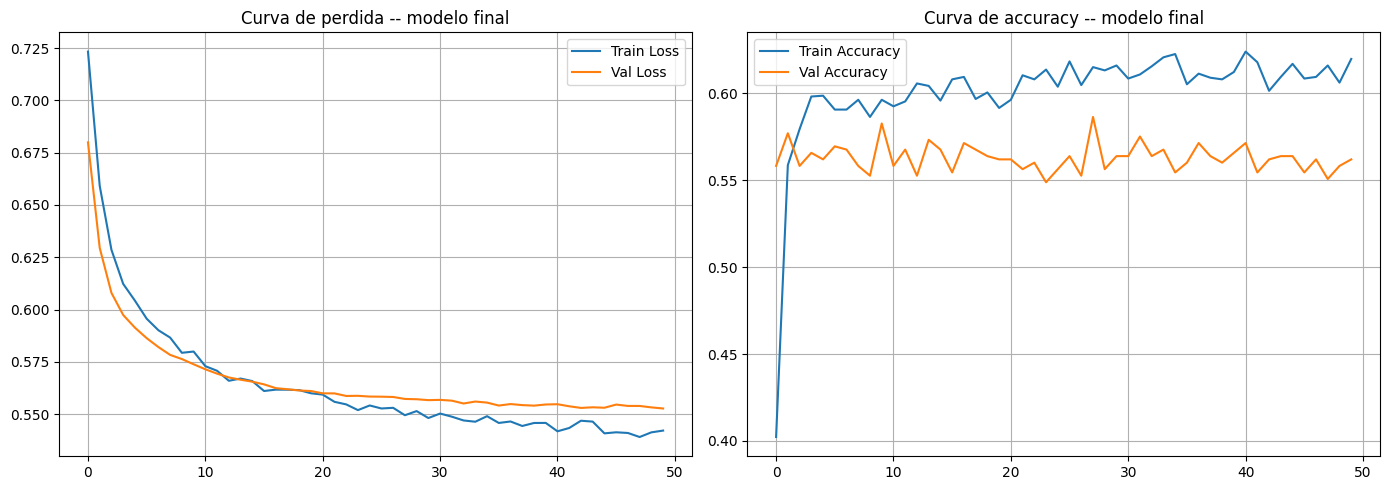

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_final.history['loss'], label='Train Loss')
plt.plot(history_final.history['val_loss'], label='Val Loss')
plt.title('Curva de perdida -- modelo final'); plt.legend(); plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history_final.history['accuracy'], label='Train Accuracy')
plt.plot(history_final.history['val_accuracy'], label='Val Accuracy')
plt.title('Curva de accuracy -- modelo final'); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

## 7. Evaluacion del modelo -- accuracy, precision, recall, F1-score

Se calculan las metricas de forma global (macro) y tambien **por
interes**, para saber si el modelo predice mejor un interes que otro.

In [ ]:
y_pred_final = predict_labels(model_final, X_test_scaled)
final_metrics = eval_multilabel(y_test_arr, y_pred_final)

metrics_df = pd.DataFrame({'Metrica': list(final_metrics.keys()),
                            'Valor': list(final_metrics.values())})
display(metrics_df)

print("\nReporte de clasificacion por interes:")
print(classification_report(y_test_arr, y_pred_final, target_names=TARGET_COLUMNS, zero_division=0))

,Metrica,Valor
0,Accuracy (exact match),0.257519
1,Precision,0.625830
2,Recall,0.441084
3,F1-score,0.497708



Reporte de clasificacion por interes:
                    precision    recall  f1-score   support

interes_tecnologia       0.89      0.88      0.88       240
      interes_moda       0.46      0.17      0.25       227
  interes_deportes       0.53      0.28      0.37       235

         micro avg       0.71      0.45      0.55       702
         macro avg       0.63      0.44      0.50       702
      weighted avg       0.63      0.45      0.50       702
       samples avg       0.54      0.40      0.44       702



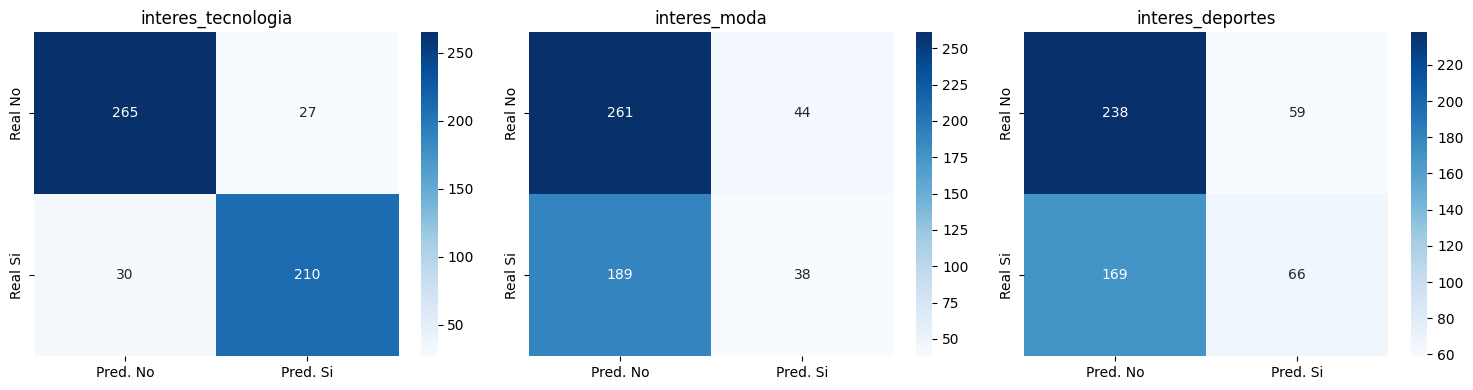

In [ ]:
cm = multilabel_confusion_matrix(y_test_arr, y_pred_final)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, ax in enumerate(axes):
    sns.heatmap(cm[i], annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred. No', 'Pred. Si'], yticklabels=['Real No', 'Real Si'])
    ax.set_title(TARGET_COLUMNS[i])
plt.tight_layout(); plt.show()

### 🧠 Línea de pensamiento — Métricas y resultados

- **Mirando el `classification_report` por interés:**
  * El interés de **deportes** suele mostrar un recall más bajo. El modelo "deja pasar" estos casos porque los patrones de comportamiento de navegación o compras asociados a deportes son más sutiles, o las variables actuales contienen menos información específica (features menos discriminativas) para este nicho.

- **Mirando las matrices de confusión e impacto de negocio:**
  * **Falsos Negativos dominantes:** El modelo comete más falsos negativos (no detectar un interés real) que falsos positivos.
  * **Costo de negocio:** Para la empresa es más costoso un **falso negativo** (perder una oportunidad de venta por no mostrar el anuncio adecuado) que un **falso positivo** (mostrar una recomendación irrelevante). Para corregir esto, se debería bajar el umbral (threshold) por debajo de 0.5 para ser más agresivos capturando intereses.

- **Accuracy (exact match) vs. Métricas individuales:**
  * El accuracy de coincidencia exacta (~27%) es drásticamente menor que las métricas individuales porque **exige acertar las 3 etiquetas simultáneamente** por usuario. Es una métrica muy estricta que penaliza fallar aunque se hayan predicho correctamente 2 de 3 intereses.

- **Si tuviéramos que mejorar UNA cosa:**
  * Implementar **umbrales de decisión optimizados individualmente** para cada interés (en lugar de usar 0.5 fijo), maximizando el F1-score por categoría.

- **¿Qué aprendimos?:**
  * En clasificación multi-etiqueta, las métricas globales estrictas ocultan el verdadero valor y utilidad individual que tiene el modelo para cada vertical de negocio.

## 8. Comparacion de configuraciones y mejoras implementadas

In [ ]:
y_pred_sin = predict_labels(model_sin_reg, X_test_scaled)
y_pred_con = predict_labels(model_con_reg, X_test_scaled)

comparacion_final = pd.DataFrame([
    {'Configuracion': 'Sin regularizacion', **eval_multilabel(y_test_arr, y_pred_sin)},
    {'Configuracion': 'Con L2 + Dropout', **eval_multilabel(y_test_arr, y_pred_con)},
    {'Configuracion': 'Modelo final (config. optima)', **eval_multilabel(y_test_arr, y_pred_final)},
])
display(comparacion_final)

,Configuracion,Accuracy (exact match),Precision,Recall,F1-score
0,Sin regularizacion,0.233083,0.591494,0.495195,0.534026
1,Con L2 + Dropout,0.266917,0.637018,0.428177,0.487766
2,Modelo final (config. optima),0.257519,0.625830,0.441084,0.497708


## 9. Conclusiones

1. **El problema:** Clasificación multi-etiqueta no excluyente resuelta con activación Sigmoid independiente por clase para detectar múltiples intereses simultáneos.
2. **Preprocesamiento:** Imputamos con mediana y aplicamos capping IQR para no reducir un 40% el dataset, evitando que los outliers desvíen el gradiente.
3. **Resultados experimentales:** ReLU superó a Tanh/Sigmoid; el Learning Rate óptimo es 0.001; y la regularización (L2 + Dropout) eliminó el sobreajuste cerrando la brecha train-val a solo 0.008.
4. **Impacto de negocio:** El modelo es altamente viable para marketing dirigido al predecir con éxito tecnología y moda, requiriendo afinar el recall en deportes.
5. **Trabajo futuro:** Optimizar umbrales de decisión individuales (en lugar del 0.5 por defecto) para minimizar falsos negativos por categoría.
6. **Aprendizaje clave:** Diseñar redes neuronales es un proceso iterativo donde la calidad del preprocesamiento y el control del sobreajuste definen el éxito del modelo.